# 02 — Exploratory Data Analysis for a regression task

## EDA with a continuous numerical target

This notebook analyzes the **processed synthetic crop-yield dataset** generated by `01_tabular_data_preprocessing.ipynb`.

Unlike classification, the target `yield_t_ha` is continuous. We therefore do not compare a fixed set of label groups. Instead, the analysis asks how the target varies across the numerical and categorical predictor space.

The workflow covers:

1. dataset structure and target distribution;
2. missingness and outlier diagnostics;
3. numerical predictor–target relationships;
4. linear, monotonic, and rank-based association tests;
5. nonlinear relationship profiles using predictor quantiles;
6. categorical predictor–target comparisons;
7. multivariable correlation structure;
8. PCA colored by the continuous target;
9. t-SNE and optional UMAP colored by crop yield.

> **Important:** this is a synthetic educational dataset. The notebook demonstrates regression-oriented EDA. It does not establish agronomic causal effects or predictive model performance.


## Learning objectives

After completing this notebook, students should be able to:

- recognize that EDA with a continuous target requires a different logic from class-conditioned EDA;
- characterize the distribution, skewness, tails, and potential outliers of a regression target;
- distinguish Pearson, Spearman, and Kendall associations;
- understand why a weak correlation does not imply absence of a nonlinear relationship;
- inspect predictor–target relationships with raw observations and robust binned summaries;
- compare a continuous target across binary categorical predictors;
- complement hypothesis tests with effect sizes and FDR correction;
- inspect multivariable geometry while representing the target as a continuous color gradient;
- avoid interpreting PCA, t-SNE, or UMAP as predictive validation.

No train/test split or regression model is fitted in this notebook.


## 1. Imports and reproducibility

The analysis uses standard scientific Python packages. UMAP is optional and is skipped gracefully if `umap-learn` is unavailable.


In [1]:
from pathlib import Path
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.multitest import multipletests

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")

PASTEL_SEQUENTIAL_CMAP = sns.light_palette("#6F9F8D", n_colors=256, as_cmap=True)
PASTEL_DIVERGING_CMAP = sns.diverging_palette(
    270, 145, s=42, l=78, center="light", as_cmap=True
)
TARGET_CMAP = sns.light_palette("#477A9F", n_colors=256, as_cmap=True)
BINARY_PALETTE = sns.color_palette("Set2", 2)
SINGLE_COLOR = sns.color_palette("Set2", 3)[0]

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("seaborn:", sns.__version__)


Python: 3.14.8
pandas: 3.0.6
seaborn: 0.13.2


## 2. Project paths

Outputs are stored separately from the processed dataset:

```text
results/synthetic_crop_yield/eda_regression/
├── figures/
└── tables/
```


In [2]:
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root. Run the notebook from inside the project."
    )


PROJECT_ROOT = find_project_root(Path.cwd())

PROCESSED_DIR = PROJECT_ROOT / "data" / "synthetic_crop_yield" / "processed_data"
PROCESSED_DATA_PATH = PROCESSED_DIR / "synthetic_crop_yield_1200_processed.csv"
PREPROCESSING_REPORT_PATH = PROCESSED_DIR / "preprocessing_report.json"

RESULTS_DIR = PROJECT_ROOT / "results" / "synthetic_crop_yield" / "eda_regression"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("Processed data:", PROCESSED_DATA_PATH.relative_to(PROJECT_ROOT))
print("EDA results:", RESULTS_DIR.relative_to(PROJECT_ROOT))


Processed data: data/synthetic_crop_yield/processed_data/synthetic_crop_yield_1200_processed.csv
EDA results: results/synthetic_crop_yield/eda_regression


## 3. Load the processed dataset and analytical roles

The preprocessing report defines the identifier, numerical predictors, categorical predictors, and continuous target. Reusing these roles keeps preprocessing and EDA consistent.


In [3]:
if not PROCESSED_DATA_PATH.exists() or not PREPROCESSING_REPORT_PATH.exists():
    raise FileNotFoundError(
        "Processed data are missing. Run task3_crop_yield/01_tabular_data_preprocessing.ipynb first."
    )

df = pd.read_csv(PROCESSED_DATA_PATH)
with PREPROCESSING_REPORT_PATH.open("r", encoding="utf-8") as file:
    preprocessing_report = json.load(file)

ID_COLUMN = preprocessing_report["identifier_column"]
TARGET_COLUMN = preprocessing_report["target_column"]
NUMERICAL_COLUMNS = list(preprocessing_report["numerical_columns"])
CATEGORICAL_COLUMNS = list(preprocessing_report["categorical_columns"])
FEATURE_COLUMNS = NUMERICAL_COLUMNS + CATEGORICAL_COLUMNS

expected_columns = {ID_COLUMN, TARGET_COLUMN, *FEATURE_COLUMNS}
missing_columns = sorted(expected_columns - set(df.columns))
if missing_columns:
    raise ValueError(f"Processed dataset is missing expected columns: {missing_columns}")

if not pd.api.types.is_numeric_dtype(df[TARGET_COLUMN]):
    raise TypeError(f"Regression target {TARGET_COLUMN!r} must be numeric.")

print("Shape:", df.shape)
print("Identifier:", ID_COLUMN)
print("Continuous target:", TARGET_COLUMN)
print("Numerical predictors:", len(NUMERICAL_COLUMNS))
print("Categorical predictors:", len(CATEGORICAL_COLUMNS))


Shape: (1200, 21)
Identifier: plot_id
Continuous target: yield_t_ha
Numerical predictors: 13
Categorical predictors: 6


# Part I — Dataset and target structure

## 4. Structural summary

The first table establishes the analytical object before any relationship is interpreted.


In [4]:
dataset_summary = pd.DataFrame(
    {
        "property": [
            "Observations",
            "Columns in processed table",
            "Numerical predictors",
            "Categorical predictors",
            "Continuous targets",
            "Missing cells",
            "Exact duplicate rows",
            "Duplicated identifiers",
        ],
        "value": [
            len(df),
            df.shape[1],
            len(NUMERICAL_COLUMNS),
            len(CATEGORICAL_COLUMNS),
            1,
            int(df.isna().sum().sum()),
            int(df.duplicated().sum()),
            int(df[ID_COLUMN].duplicated().sum()),
        ],
    }
)
dataset_summary.to_csv(TABLES_DIR / "dataset_summary.csv", index=False)
display(dataset_summary)


,property,value
0,Observations,1200
1,Columns in processed table,21
2,Numerical predictors,13
3,Categorical predictors,6
4,Continuous targets,1
5,Missing cells,0
6,Exact duplicate rows,0
7,Duplicated identifiers,0


## 5. Distribution of the continuous target

For regression, the target itself deserves a full univariate inspection. We report center, spread, quantiles, skewness, and kurtosis, and inspect both the empirical distribution and a normal Q–Q plot.

A Q–Q plot is a diagnostic visualization, not a requirement that the target must be normally distributed. Most regression algorithms do **not** require the raw target itself to be normal.


,statistic,value
0,n,1200.0000
1,mean,4.2815
2,std,1.4701
3,min,0.7000
4,q1,3.2800
5,median,4.4300
6,q3,5.3200
7,max,8.1100
8,iqr,2.0400
9,skewness,-0.3396


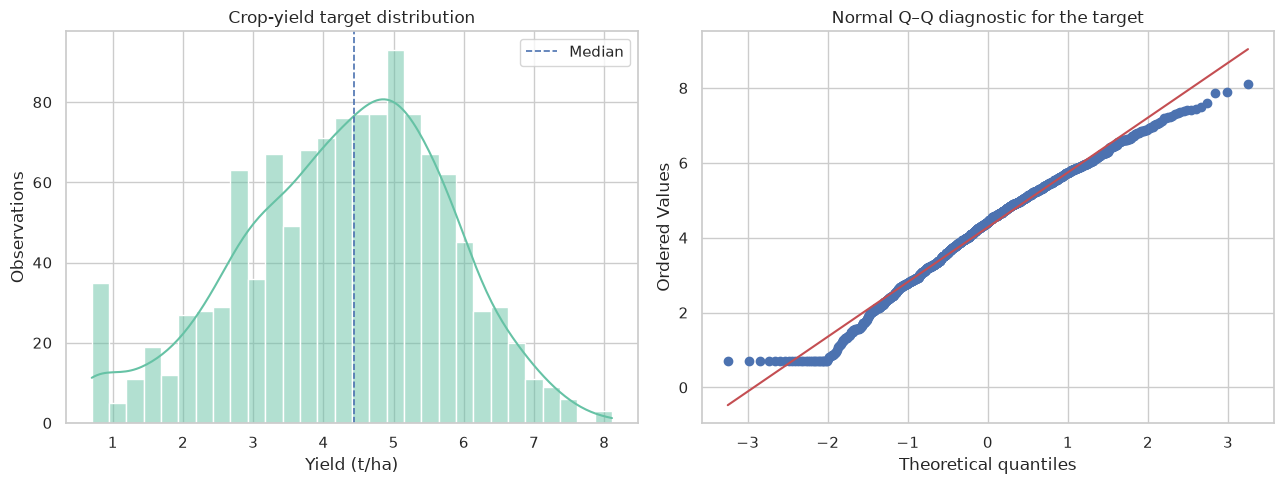

In [5]:
target = df[TARGET_COLUMN].dropna()
q1, q3 = target.quantile([0.25, 0.75])
target_summary = pd.DataFrame(
    {
        "statistic": [
            "n", "mean", "std", "min", "q1", "median", "q3", "max", "iqr", "skewness", "excess_kurtosis"
        ],
        "value": [
            len(target),
            target.mean(),
            target.std(ddof=1),
            target.min(),
            q1,
            target.median(),
            q3,
            target.max(),
            q3 - q1,
            stats.skew(target, bias=False),
            stats.kurtosis(target, fisher=True, bias=False),
        ],
    }
)
target_summary.to_csv(TABLES_DIR / "target_summary.csv", index=False)
display(target_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(data=df, x=TARGET_COLUMN, kde=True, bins=30, color=SINGLE_COLOR, ax=axes[0])
axes[0].axvline(target.median(), linestyle="--", linewidth=1.2, label="Median")
axes[0].set(title="Crop-yield target distribution", xlabel="Yield (t/ha)", ylabel="Observations")
axes[0].legend()

stats.probplot(target, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q–Q diagnostic for the target")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_target_distribution_and_qq.png", dpi=180, bbox_inches="tight")
plt.show()


## 6. Missingness

Missingness is assessed for predictors and target. In a regression setting, missing target values are especially important because they cannot contribute directly to supervised training later.


In [6]:
missingness = pd.DataFrame(
    {
        "feature": FEATURE_COLUMNS + [TARGET_COLUMN],
        "missing_count": [int(df[column].isna().sum()) for column in FEATURE_COLUMNS + [TARGET_COLUMN]],
    }
)
missingness["missing_percentage"] = 100 * missingness["missing_count"] / len(df)
missingness.to_csv(TABLES_DIR / "missingness.csv", index=False)

display(missingness)


,feature,missing_count,missing_percentage
0,mean_temperature_c,0,0.0
1,season_rainfall_mm,0,0.0
2,soil_ph,0,0.0
3,soil_organic_matter_pct,0,0.0
4,nitrogen_kg_ha,0,0.0
5,phosphorus_kg_ha,0,0.0
6,potassium_kg_ha,0,0.0
7,irrigation_mm,0,0.0
8,solar_radiation_mj_m2_day,0,0.0
9,field_slope_pct,0,0.0


# Part II — Predictor distributions and outliers

## 7. Numerical predictor distributions

Before relating predictors to yield, inspect their marginal distributions. This helps identify skewness, truncation, discrete variables, and unusual tails that may affect later visual and statistical interpretation.


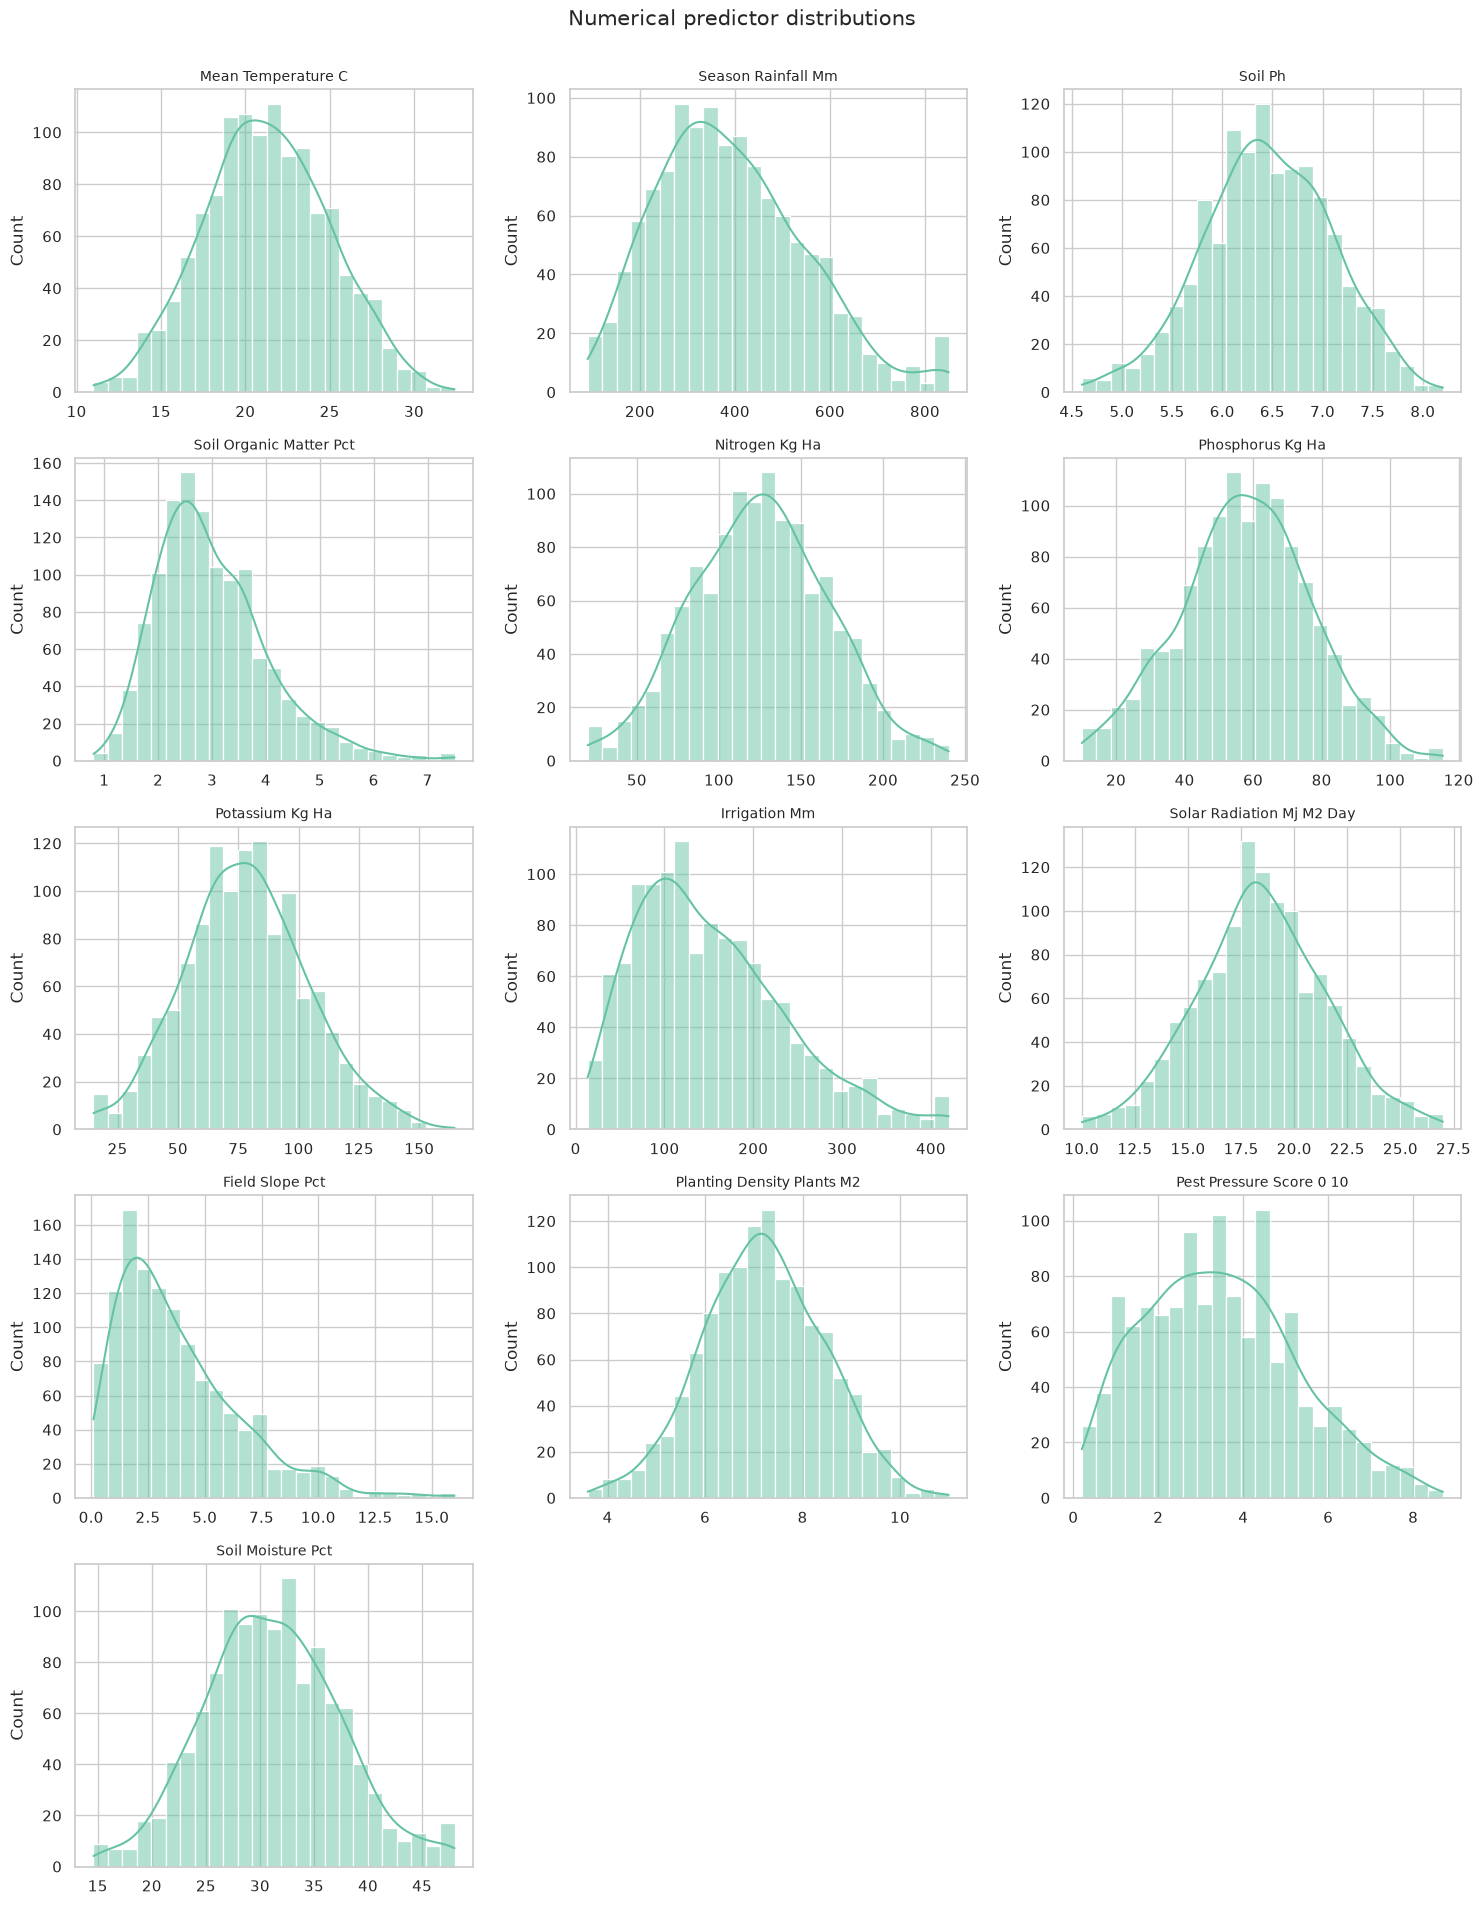

In [7]:
ncols = 3
nrows = int(np.ceil(len(NUMERICAL_COLUMNS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.8 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, feature in zip(axes, NUMERICAL_COLUMNS):
    sns.histplot(data=df, x=feature, kde=True, bins=25, color=SINGLE_COLOR, ax=ax)
    ax.set_title(feature.replace("_", " ").title(), fontsize=10)
    ax.set_xlabel("")

for ax in axes[len(NUMERICAL_COLUMNS):]:
    ax.remove()

fig.suptitle("Numerical predictor distributions", y=1.002, fontsize=15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_numerical_predictor_distributions.png", dpi=180, bbox_inches="tight")
plt.show()


## 8. IQR outlier diagnostics

The IQR rule is applied to every numerical predictor and to the continuous target. These flags identify unusual observations; they do **not** justify automatic removal.

In scientific datasets, extreme values can represent measurement problems, rare but legitimate cases, or informative regions of the design space. Their meaning must be investigated before any cleaning decision.


,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
9,field_slope_pct,-3.300,10.300,32,2.667
3,soil_organic_matter_pct,0.325,5.485,30,2.500
7,irrigation_mm,-82.862,370.838,23,1.917
1,season_rainfall_mm,-43.725,810.675,20,1.667
12,soil_moisture_pct,14.300,47.900,10,0.833
6,potassium_kg_ha,11.350,144.750,9,0.750
8,solar_radiation_mj_m2_day,10.500,26.500,9,0.750
10,planting_density_plants_m2,3.790,10.590,7,0.583
2,soil_ph,4.750,8.190,7,0.583
5,phosphorus_kg_ha,8.038,107.337,6,0.500


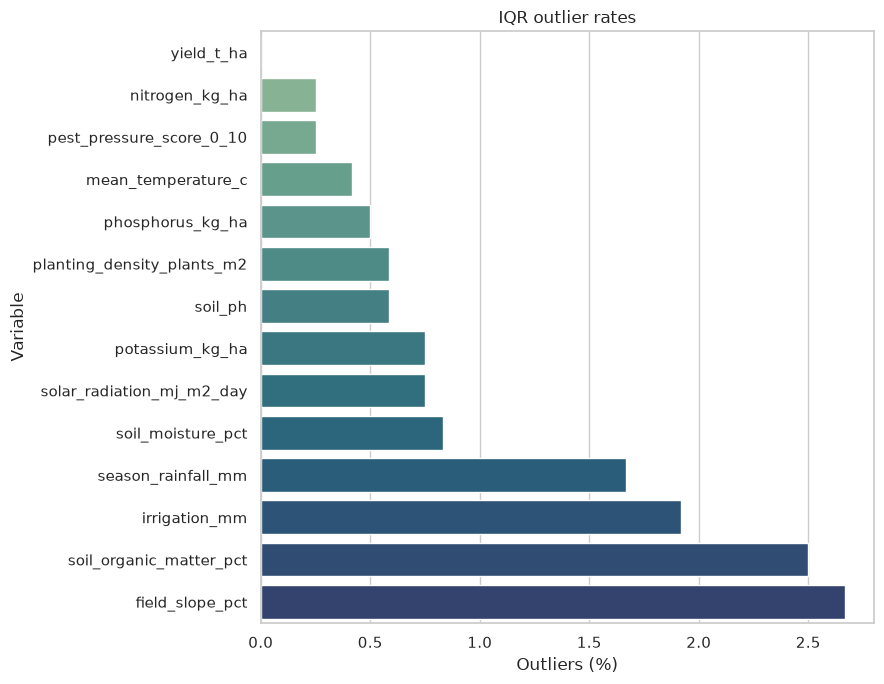

In [8]:
outlier_records = []
for feature in NUMERICAL_COLUMNS + [TARGET_COLUMN]:
    values = df[feature].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (values < lower) | (values > upper)
    outlier_records.append(
        {
            "feature": feature,
            "lower_bound": lower,
            "upper_bound": upper,
            "outlier_count": int(mask.sum()),
            "outlier_percentage": 100 * mask.mean(),
        }
    )

outliers = pd.DataFrame(outlier_records).sort_values("outlier_percentage", ascending=False)
outliers.to_csv(TABLES_DIR / "iqr_outliers.csv", index=False)
display(outliers.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(
    data=outliers.sort_values("outlier_percentage", ascending=True),
    x="outlier_percentage",
    y="feature",
    hue="feature",
    palette=sns.color_palette("crest", n_colors=len(outliers)),
    legend=False,
    ax=ax,
)
ax.set(title="IQR outlier rates", xlabel="Outliers (%)", ylabel="Variable")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_outlier_rates.png", dpi=180, bbox_inches="tight")
plt.show()


# Part III — Numerical predictors versus a continuous target

## 9. Pearson, Spearman, and Kendall associations

A regression-oriented EDA should not rely on a single correlation coefficient.

- **Pearson** measures linear association;
- **Spearman** measures monotonic rank association;
- **Kendall's tau** measures ordinal concordance and is also rank-based.

A feature can have a weak Pearson and Spearman correlation while still having a strong **nonlinear** relationship with the target. This is especially important for variables with an optimum range, U-shaped effects, thresholds, or saturation.

P-values are corrected for multiple testing separately for each correlation family using Benjamini–Hochberg FDR.


In [9]:
correlation_records = []
for feature in NUMERICAL_COLUMNS:
    x = df[feature].to_numpy()
    y = df[TARGET_COLUMN].to_numpy()

    pearson = stats.pearsonr(x, y)
    spearman = stats.spearmanr(x, y)
    kendall = stats.kendalltau(x, y)

    correlation_records.append(
        {
            "feature": feature,
            "pearson_r": pearson.statistic,
            "pearson_p": pearson.pvalue,
            "spearman_rho": spearman.statistic,
            "spearman_p": spearman.pvalue,
            "kendall_tau": kendall.statistic,
            "kendall_p": kendall.pvalue,
        }
    )

correlation_tests = pd.DataFrame(correlation_records)
for p_col, q_col in [
    ("pearson_p", "pearson_q_fdr"),
    ("spearman_p", "spearman_q_fdr"),
    ("kendall_p", "kendall_q_fdr"),
]:
    correlation_tests[q_col] = multipletests(correlation_tests[p_col], method="fdr_bh")[1]

correlation_tests["abs_spearman_rho"] = correlation_tests["spearman_rho"].abs()
correlation_tests = correlation_tests.sort_values("abs_spearman_rho", ascending=False).reset_index(drop=True)
correlation_tests.to_csv(TABLES_DIR / "numerical_target_correlations.csv", index=False)
display(correlation_tests.round(4))


,feature,pearson_r,pearson_p,spearman_rho,spearman_p,kendall_tau,kendall_p,pearson_q_fdr,spearman_q_fdr,kendall_q_fdr,abs_spearman_rho
0,pest_pressure_score_0_10,-0.2635,0.0000,-0.2576,0.0000,-0.1762,0.0000,0.0000,0.0000,0.0000,0.2576
1,season_rainfall_mm,0.1257,0.0000,0.1711,0.0000,0.1181,0.0000,0.0000,0.0000,0.0000,0.1711
2,soil_organic_matter_pct,0.1957,0.0000,0.1671,0.0000,0.1120,0.0000,0.0000,0.0000,0.0000,0.1671
3,nitrogen_kg_ha,0.1429,0.0000,0.1398,0.0000,0.0941,0.0000,0.0000,0.0000,0.0000,0.1398
4,solar_radiation_mj_m2_day,0.1456,0.0000,0.1371,0.0000,0.0920,0.0000,0.0000,0.0000,0.0000,0.1371
5,field_slope_pct,-0.1245,0.0000,-0.1125,0.0001,-0.0763,0.0001,0.0000,0.0002,0.0002,0.1125
6,soil_moisture_pct,-0.1001,0.0005,-0.0799,0.0056,-0.0542,0.0051,0.0010,0.0104,0.0094,0.0799
7,irrigation_mm,-0.0778,0.0070,-0.0406,0.1601,-0.0278,0.1493,0.0114,0.2602,0.2427,0.0406
8,mean_temperature_c,0.0245,0.3957,0.0234,0.4170,0.0164,0.3972,0.5144,0.5793,0.5738,0.0234
9,phosphorus_kg_ha,0.0186,0.5203,0.0220,0.4456,0.0138,0.4764,0.6149,0.5793,0.5968,0.0220


## 10. Compare correlation coefficients visually

Displaying the three coefficients together makes disagreement visible. For example, a strong monotonic but nonlinear trend may produce a larger Spearman coefficient than Pearson correlation.

However, even all three coefficients can miss a non-monotonic relationship. We address that next.


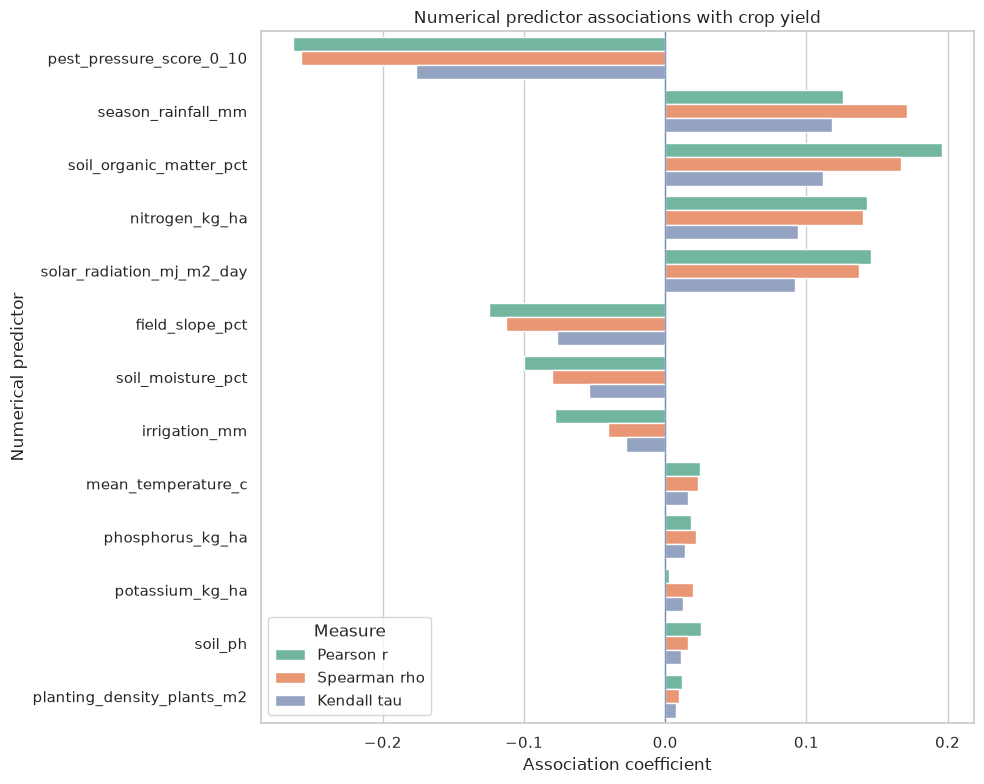

In [10]:
correlation_long = correlation_tests.melt(
    id_vars="feature",
    value_vars=["pearson_r", "spearman_rho", "kendall_tau"],
    var_name="association",
    value_name="coefficient",
)
correlation_long["association"] = correlation_long["association"].map(
    {
        "pearson_r": "Pearson r",
        "spearman_rho": "Spearman rho",
        "kendall_tau": "Kendall tau",
    }
)

feature_order = correlation_tests["feature"].tolist()
fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(
    data=correlation_long,
    x="coefficient",
    y="feature",
    hue="association",
    order=feature_order,
    palette="Set2",
    ax=ax,
)
ax.axvline(0, linewidth=1, alpha=0.7)
ax.set(title="Numerical predictor associations with crop yield", xlabel="Association coefficient", ylabel="Numerical predictor")
ax.legend(title="Measure")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_target_correlation_comparison.png", dpi=180, bbox_inches="tight")
plt.show()


## 11. Quantile profiles for nonlinear relationships

Correlation coefficients summarize a relationship into one number. To inspect nonlinear structure without fitting a predictive model, each numerical predictor is divided into approximately ten equal-frequency bins.

For each bin we calculate:

- median predictor value;
- median target;
- target Q1 and Q3;
- number of observations.

The **quantile-profile range** is the difference between the largest and smallest bin-level median yield. It is a simple exploratory quantity, not a formal effect size. It can highlight variables whose relationship with yield is strong but non-monotonic.


In [11]:
profile_frames = []
profile_strength_records = []

for feature in NUMERICAL_COLUMNS:
    temp = df[[feature, TARGET_COLUMN]].dropna().copy()
    temp["bin"] = pd.qcut(temp[feature], q=10, duplicates="drop")

    profile = (
        temp.groupby("bin", observed=True)
        .agg(
            predictor_median=(feature, "median"),
            target_median=(TARGET_COLUMN, "median"),
            target_q1=(TARGET_COLUMN, lambda x: x.quantile(0.25)),
            target_q3=(TARGET_COLUMN, lambda x: x.quantile(0.75)),
            n=(TARGET_COLUMN, "size"),
        )
        .reset_index(drop=True)
    )
    profile.insert(0, "feature", feature)
    profile_frames.append(profile)

    profile_strength_records.append(
        {
            "feature": feature,
            "median_target_range_across_deciles": profile["target_median"].max() - profile["target_median"].min(),
        }
    )

quantile_profiles = pd.concat(profile_frames, ignore_index=True)
profile_strength = pd.DataFrame(profile_strength_records).sort_values(
    "median_target_range_across_deciles", ascending=False
)

quantile_profiles.to_csv(TABLES_DIR / "numerical_target_quantile_profiles.csv", index=False)
profile_strength.to_csv(TABLES_DIR / "quantile_profile_strength.csv", index=False)

display(profile_strength.round(3))


,feature,median_target_range_across_deciles
0,mean_temperature_c,2.240
12,soil_moisture_pct,1.830
11,pest_pressure_score_0_10,1.230
1,season_rainfall_mm,1.180
4,nitrogen_kg_ha,1.140
3,soil_organic_matter_pct,1.040
9,field_slope_pct,0.995
8,solar_radiation_mj_m2_day,0.910
7,irrigation_mm,0.805
5,phosphorus_kg_ha,0.770


## 12. Visualize the strongest quantile profiles

The six numerical predictors with the largest variation in bin-level median yield are shown below.

Raw observations remain visible with low opacity. The thicker line connects the median yield in predictor quantiles, and the shaded band shows the target interquartile range within each bin.

This allows linear, monotonic, U-shaped, inverted-U, threshold, and saturation-like patterns to be seen without treating an exploratory smoother as a predictive model.


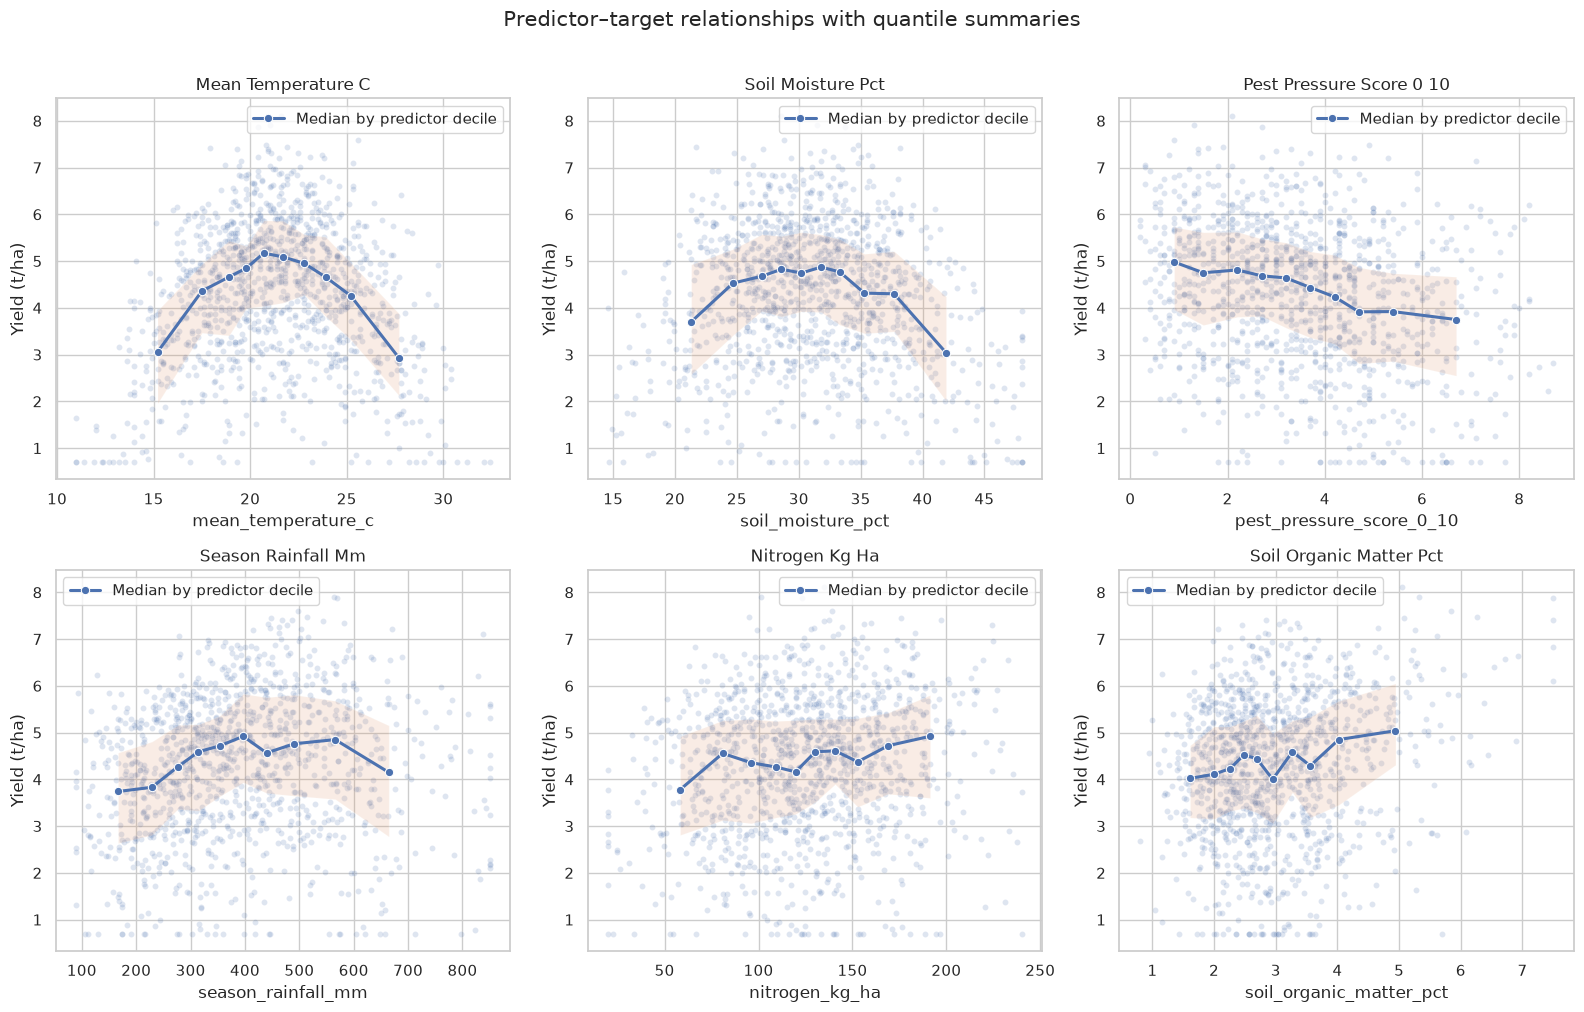

In [12]:
TOP_PROFILE_FEATURES = profile_strength.head(6)["feature"].tolist()

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for ax, feature in zip(axes, TOP_PROFILE_FEATURES):
    sns.scatterplot(
        data=df,
        x=feature,
        y=TARGET_COLUMN,
        alpha=0.18,
        s=18,
        ax=ax,
        legend=False,
    )

    profile = quantile_profiles.loc[quantile_profiles["feature"] == feature]
    sns.lineplot(
        data=profile,
        x="predictor_median",
        y="target_median",
        marker="o",
        linewidth=2.2,
        ax=ax,
        label="Median by predictor decile",
    )
    ax.fill_between(
        profile["predictor_median"],
        profile["target_q1"],
        profile["target_q3"],
        alpha=0.15,
        label="Target IQR",
    )
    ax.set_title(feature.replace("_", " ").title())
    ax.set_ylabel("Yield (t/ha)")

fig.suptitle("Predictor–target relationships with quantile summaries", y=1.01, fontsize=15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_quantile_profile_relationships.png", dpi=180, bbox_inches="tight")
plt.show()


# Part IV — Binary categorical predictors versus a continuous target

## 13. Target distributions by categorical predictor

For a binary categorical predictor, the natural regression-oriented question is not “what is the prevalence by label?”, because the target is continuous. Instead, we compare the **distribution of crop yield** between the two categories.

Boxplots show median, interquartile range, and tails for `0` versus `1` within each categorical predictor.


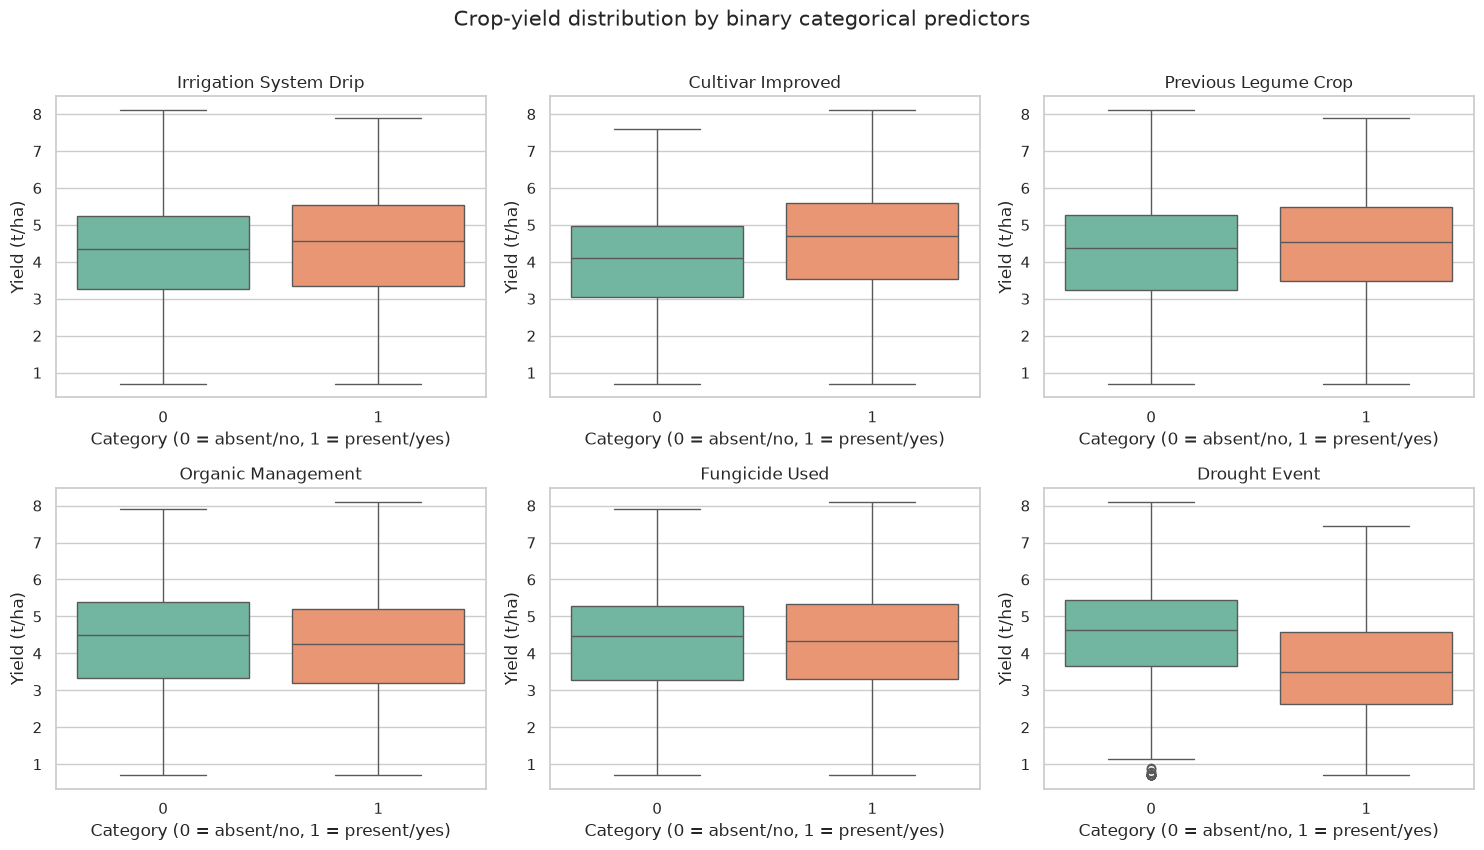

In [13]:
ncols = 3
nrows = int(np.ceil(len(CATEGORICAL_COLUMNS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.2 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, feature in zip(axes, CATEGORICAL_COLUMNS):
    sns.boxplot(
        data=df,
        x=feature,
        y=TARGET_COLUMN,
        hue=feature,
        palette=BINARY_PALETTE,
        legend=False,
        ax=ax,
    )
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Category (0 = absent/no, 1 = present/yes)")
    ax.set_ylabel("Yield (t/ha)")

for ax in axes[len(CATEGORICAL_COLUMNS):]:
    ax.remove()

fig.suptitle("Crop-yield distribution by binary categorical predictors", y=1.01, fontsize=15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_target_by_categorical_predictors.png", dpi=180, bbox_inches="tight")
plt.show()


## 14. Statistical comparison for binary categorical predictors

For each binary predictor we compare target values between category `0` and category `1` using:

- Welch's t-test for a mean-based comparison without assuming equal variances;
- Mann–Whitney U for a rank-based comparison;
- Hedges' g as a standardized mean difference;
- Cliff's delta as a rank-based effect size.

P-values are corrected for multiple comparisons using FDR. Statistical significance and effect magnitude should be interpreted together.


In [14]:
def hedges_g(a: np.ndarray, b: np.ndarray) -> float:
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    n1, n2 = len(a), len(b)
    pooled_var = ((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2)
    if pooled_var <= 0:
        return np.nan
    d = (a.mean() - b.mean()) / np.sqrt(pooled_var)
    correction = 1 - 3 / (4 * (n1 + n2) - 9)
    return correction * d


categorical_records = []
for feature in CATEGORICAL_COLUMNS:
    group0 = df.loc[df[feature] == 0, TARGET_COLUMN].dropna().to_numpy()
    group1 = df.loc[df[feature] == 1, TARGET_COLUMN].dropna().to_numpy()

    welch = stats.ttest_ind(group1, group0, equal_var=False)
    mw = stats.mannwhitneyu(group1, group0, alternative="two-sided")
    cliff_delta = 2 * mw.statistic / (len(group1) * len(group0)) - 1

    categorical_records.append(
        {
            "feature": feature,
            "n_0": len(group0),
            "n_1": len(group1),
            "mean_0": group0.mean(),
            "mean_1": group1.mean(),
            "median_0": np.median(group0),
            "median_1": np.median(group1),
            "welch_t": welch.statistic,
            "welch_p": welch.pvalue,
            "mannwhitney_U": mw.statistic,
            "mannwhitney_p": mw.pvalue,
            "hedges_g_1_vs_0": hedges_g(group1, group0),
            "cliffs_delta_1_vs_0": cliff_delta,
        }
    )

categorical_target_tests = pd.DataFrame(categorical_records)
categorical_target_tests["welch_q_fdr"] = multipletests(
    categorical_target_tests["welch_p"], method="fdr_bh"
)[1]
categorical_target_tests["mannwhitney_q_fdr"] = multipletests(
    categorical_target_tests["mannwhitney_p"], method="fdr_bh"
)[1]
categorical_target_tests["abs_cliffs_delta"] = categorical_target_tests["cliffs_delta_1_vs_0"].abs()
categorical_target_tests = categorical_target_tests.sort_values(
    "abs_cliffs_delta", ascending=False
).reset_index(drop=True)

categorical_target_tests.to_csv(TABLES_DIR / "categorical_target_tests.csv", index=False)
display(categorical_target_tests.round(4))


,feature,n_0,n_1,mean_0,mean_1,median_0,median_1,welch_t,welch_p,mannwhitney_U,mannwhitney_p,hedges_g_1_vs_0,cliffs_delta_1_vs_0,welch_q_fdr,mannwhitney_q_fdr,abs_cliffs_delta
0,drought_event,936,264,4.4929,3.5323,4.645,3.490,-9.4496,0.0000,76829.5,0.0000,-0.6781,-0.3782,0.0000,0.0000,0.3782
1,cultivar_improved,508,692,3.9394,4.5327,4.110,4.705,7.0551,0.0000,216668.5,0.0000,0.4114,0.2327,0.0000,0.0000,0.2327
2,organic_management,909,291,4.3252,4.1452,4.500,4.260,-1.8829,0.0603,121899.0,0.0441,-0.1225,-0.0783,0.0723,0.0534,0.0783
3,irrigation_system_drip,737,463,4.2163,4.3854,4.340,4.560,1.9026,0.0574,183153.5,0.0319,0.1151,0.0735,0.0723,0.0534,0.0735
4,previous_legume_crop,842,358,4.2248,4.4150,4.375,4.550,2.0264,0.0431,161757.0,0.0445,0.1295,0.0732,0.0723,0.0534,0.0732
5,fungicide_used,644,556,4.3086,4.2502,4.465,4.340,-0.6866,0.4925,174828.0,0.4826,-0.0397,-0.0235,0.4925,0.4826,0.0235


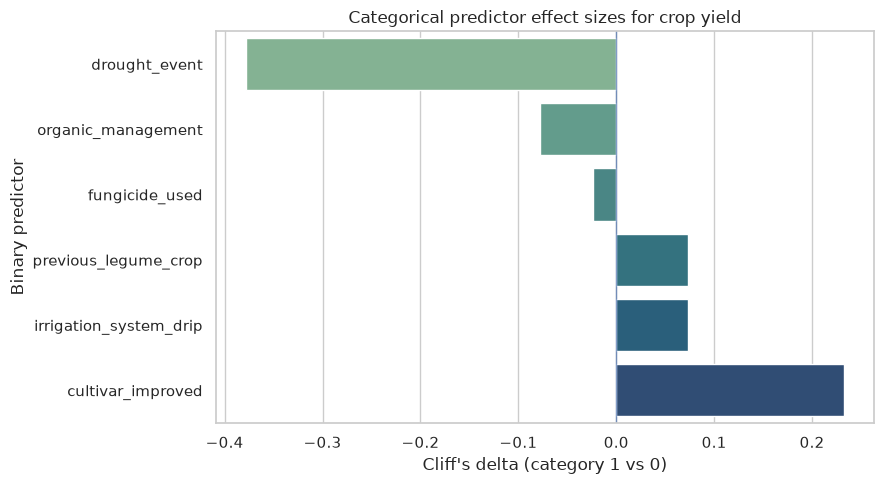

In [15]:
plot_df = categorical_target_tests.sort_values("cliffs_delta_1_vs_0")
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=plot_df,
    x="cliffs_delta_1_vs_0",
    y="feature",
    hue="feature",
    palette=sns.color_palette("crest", n_colors=len(plot_df)),
    legend=False,
    ax=ax,
)
ax.axvline(0, linewidth=1, alpha=0.7)
ax.set(title="Categorical predictor effect sizes for crop yield", xlabel="Cliff's delta (category 1 vs 0)", ylabel="Binary predictor")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_categorical_effect_sizes.png", dpi=180, bbox_inches="tight")
plt.show()


# Part V — Multivariable dependence structure

## 15. Spearman correlation matrix including the continuous target

A single target-correlation table does not show redundancy among predictors. The matrix below includes all numerical predictors plus crop yield.

Spearman correlation is used because it is less dependent on linearity than Pearson correlation, although it still summarizes only monotonic relationships.


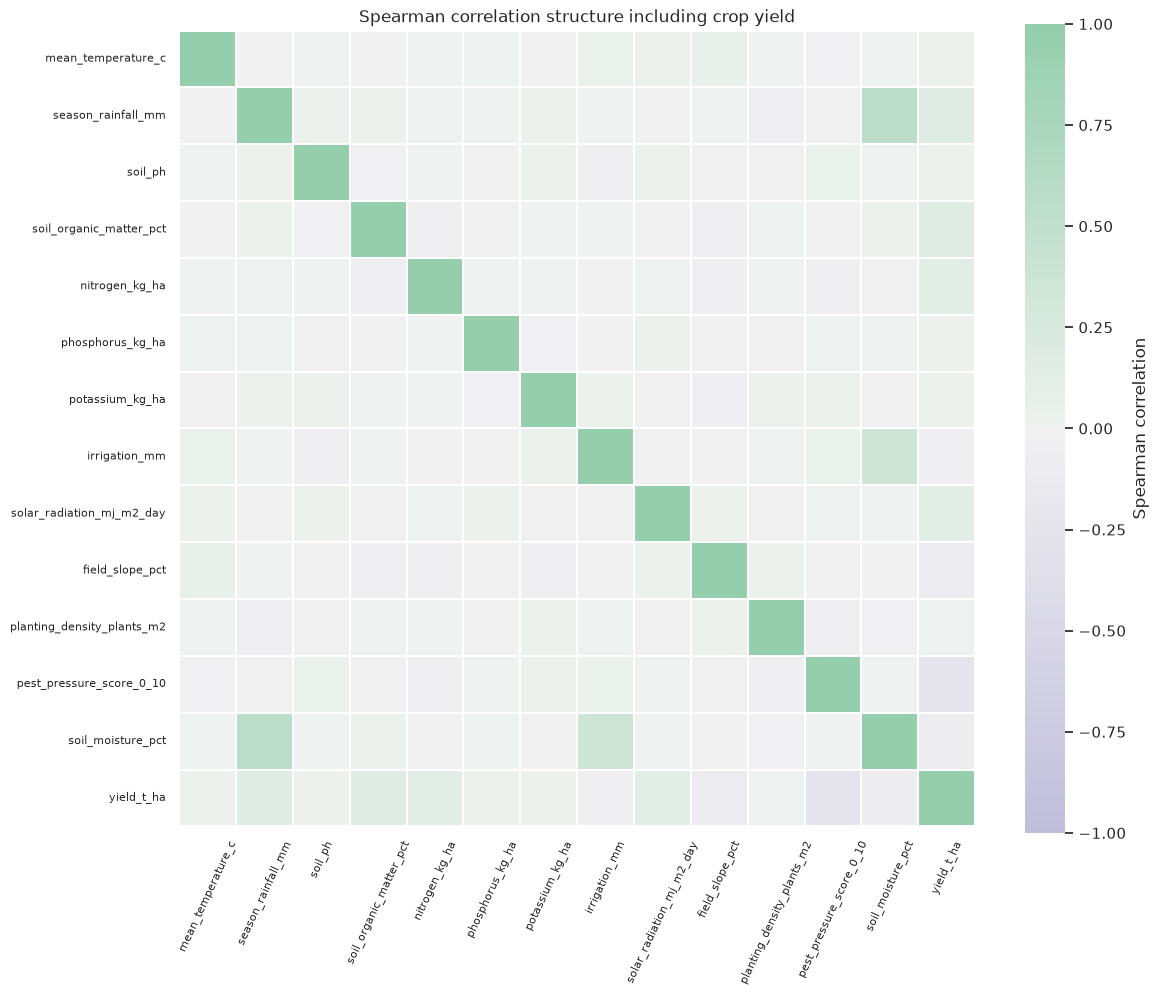

In [16]:
correlation_matrix = df[NUMERICAL_COLUMNS + [TARGET_COLUMN]].corr(method="spearman")
correlation_matrix.to_csv(TABLES_DIR / "spearman_correlation_matrix.csv")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    correlation_matrix,
    vmin=-1,
    vmax=1,
    center=0,
    cmap=PASTEL_DIVERGING_CMAP,
    square=True,
    linewidths=0.25,
    cbar_kws={"label": "Spearman correlation"},
    ax=ax,
)
ax.set_title("Spearman correlation structure including crop yield")
ax.tick_params(axis="x", rotation=65, labelsize=8)
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "08_spearman_correlation_matrix.png", dpi=180, bbox_inches="tight")
plt.show()


# Part VI — Multivariable geometry with a continuous target

## 16. Standardize predictors before projection

All predictors are standardized before PCA, t-SNE, and UMAP. The crop-yield target is **excluded** from the projection matrix.

The continuous target is added only after projection to color the points. This lets us ask whether regions of predictor space correspond to gradual yield changes without using yield to construct the geometry itself.


In [17]:
X = df[FEATURE_COLUMNS].astype(float)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Projection matrix shape:", X_scaled.shape)
print("Target included in projection matrix:", TARGET_COLUMN in FEATURE_COLUMNS)


Projection matrix shape: (1200, 19)
Target included in projection matrix: False


## 17. PCA explained variance and scores

PCA identifies linear directions of maximum predictor variance. It does **not** identify directions that best predict yield.

When PCA scores are colored by yield, smooth color gradients can suggest that some unsupervised directions align with the continuous target. Their absence does not imply that the target is unpredictable, because relevant relationships may be nonlinear or distributed across later components.


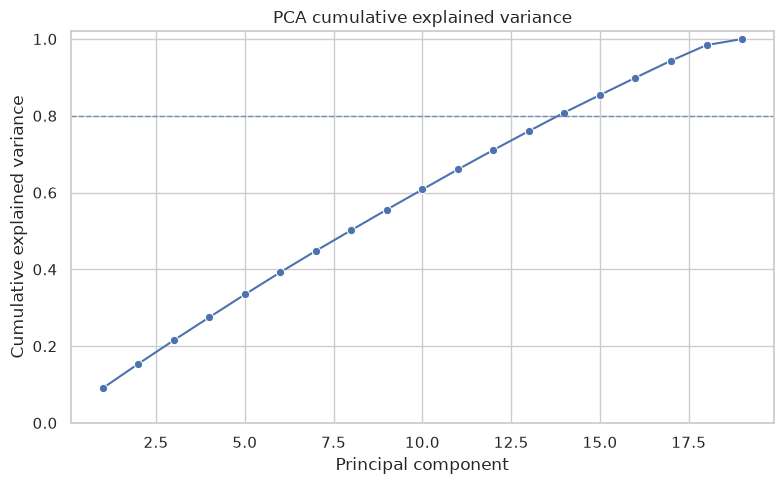

In [18]:
pca_full = PCA().fit(X_scaled)
explained = pd.DataFrame(
    {
        "component": np.arange(1, len(pca_full.explained_variance_ratio_) + 1),
        "explained_variance_ratio": pca_full.explained_variance_ratio_,
        "cumulative_explained_variance": np.cumsum(pca_full.explained_variance_ratio_),
    }
)
explained.to_csv(TABLES_DIR / "pca_explained_variance.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
sns.lineplot(data=explained, x="component", y="cumulative_explained_variance", marker="o", ax=ax)
ax.axhline(0.80, linestyle="--", linewidth=1, alpha=0.7)
ax.set(title="PCA cumulative explained variance", xlabel="Principal component", ylabel="Cumulative explained variance")
ax.set_ylim(0, 1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "09_pca_explained_variance.png", dpi=180, bbox_inches="tight")
plt.show()


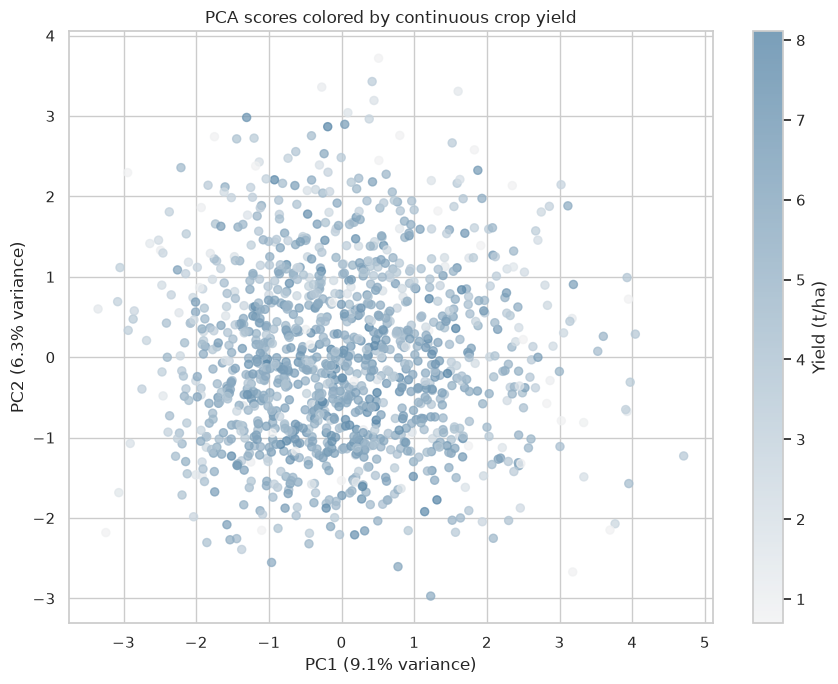

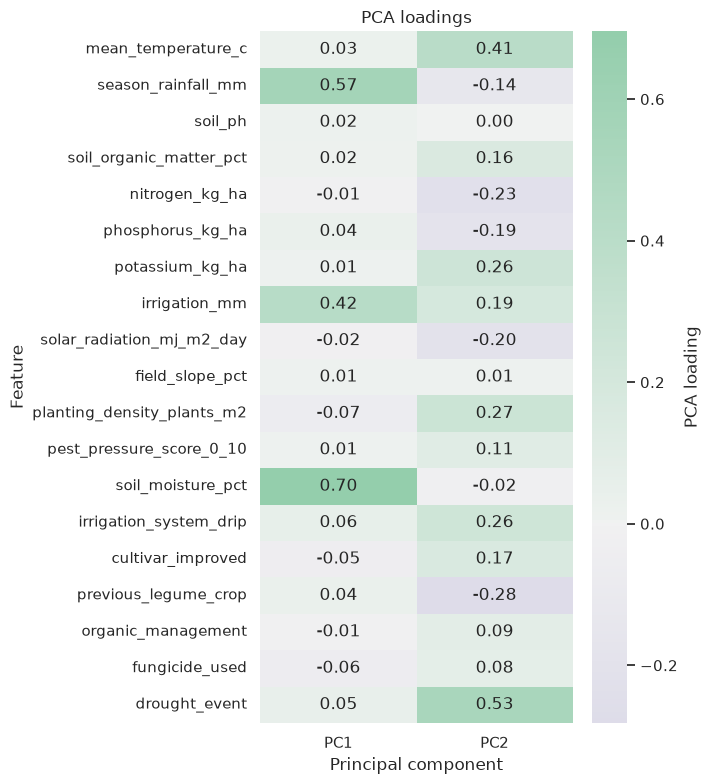

In [19]:
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

pca_scores = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_scores[TARGET_COLUMN] = df[TARGET_COLUMN].to_numpy()
pca_scores.to_csv(TABLES_DIR / "pca_scores.csv", index=False)

loadings = pd.DataFrame(
    pca_2d.components_.T,
    index=FEATURE_COLUMNS,
    columns=["PC1", "PC2"],
)
loadings.to_csv(TABLES_DIR / "pca_loadings.csv")

fig, ax = plt.subplots(figsize=(9, 7))
points = ax.scatter(
    pca_scores["PC1"],
    pca_scores["PC2"],
    c=pca_scores[TARGET_COLUMN],
    cmap=TARGET_CMAP,
    s=34,
    alpha=0.72,
)
cbar = fig.colorbar(points, ax=ax)
cbar.set_label("Yield (t/ha)")
ax.set(
    title="PCA scores colored by continuous crop yield",
    xlabel=f"PC1 ({100 * pca_2d.explained_variance_ratio_[0]:.1f}% variance)",
    ylabel=f"PC2 ({100 * pca_2d.explained_variance_ratio_[1]:.1f}% variance)",
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "10_pca_scores_by_target.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(
    loadings,
    annot=True,
    fmt=".2f",
    cmap=PASTEL_DIVERGING_CMAP,
    center=0,
    cbar_kws={"label": "PCA loading"},
    ax=ax,
)
ax.set(title="PCA loadings", xlabel="Principal component", ylabel="Feature")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "11_pca_loadings.png", dpi=180, bbox_inches="tight")
plt.show()


## 18. Association between PCA components and the continuous target

Because PCA is unsupervised, the first components are not guaranteed to align with crop yield. We therefore report Pearson and Spearman associations between PC1/PC2 and the target only as an **interpretive diagnostic** after PCA has been fitted without the target.


In [20]:
pc_target_records = []
for component in ["PC1", "PC2"]:
    pearson = stats.pearsonr(pca_scores[component], pca_scores[TARGET_COLUMN])
    spearman = stats.spearmanr(pca_scores[component], pca_scores[TARGET_COLUMN])
    pc_target_records.append(
        {
            "component": component,
            "pearson_r": pearson.statistic,
            "pearson_p": pearson.pvalue,
            "spearman_rho": spearman.statistic,
            "spearman_p": spearman.pvalue,
        }
    )

pc_target_association = pd.DataFrame(pc_target_records)
pc_target_association.to_csv(TABLES_DIR / "pca_target_association.csv", index=False)
display(pc_target_association.round(4))


,component,pearson_r,pearson_p,spearman_rho,spearman_p
0,PC1,-0.0378,0.1907,-0.0025,0.93
1,PC2,-0.1810,0.0000,-0.1692,0.00


## 19. t-SNE colored by continuous yield

t-SNE emphasizes local neighborhoods rather than global metric structure. The target is shown as a continuous color gradient.

Look for gradual color organization rather than treating visual “clusters” as regression predictions. t-SNE itself has not seen the target.


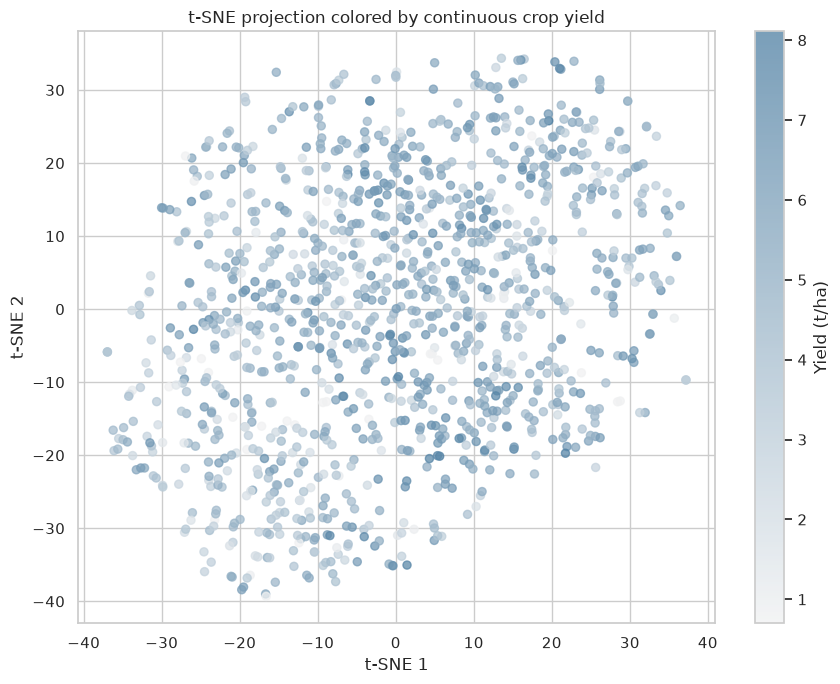

In [21]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=RANDOM_STATE,
)
X_tsne = tsne.fit_transform(X_scaled)

tsne_scores = pd.DataFrame(X_tsne, columns=["tSNE1", "tSNE2"])
tsne_scores[TARGET_COLUMN] = df[TARGET_COLUMN].to_numpy()
tsne_scores.to_csv(TABLES_DIR / "tsne_scores.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 7))
points = ax.scatter(
    tsne_scores["tSNE1"],
    tsne_scores["tSNE2"],
    c=tsne_scores[TARGET_COLUMN],
    cmap=TARGET_CMAP,
    s=34,
    alpha=0.72,
)
cbar = fig.colorbar(points, ax=ax)
cbar.set_label("Yield (t/ha)")
ax.set(title="t-SNE projection colored by continuous crop yield", xlabel="t-SNE 1", ylabel="t-SNE 2")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "12_tsne_by_target.png", dpi=180, bbox_inches="tight")
plt.show()


## 20. Optional UMAP colored by continuous yield

UMAP provides a second nonlinear view of local neighborhood structure. The same interpretive caution applies: the color pattern is exploratory and is not a performance estimate.


/home/david/miniconda3/envs/ml2026/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


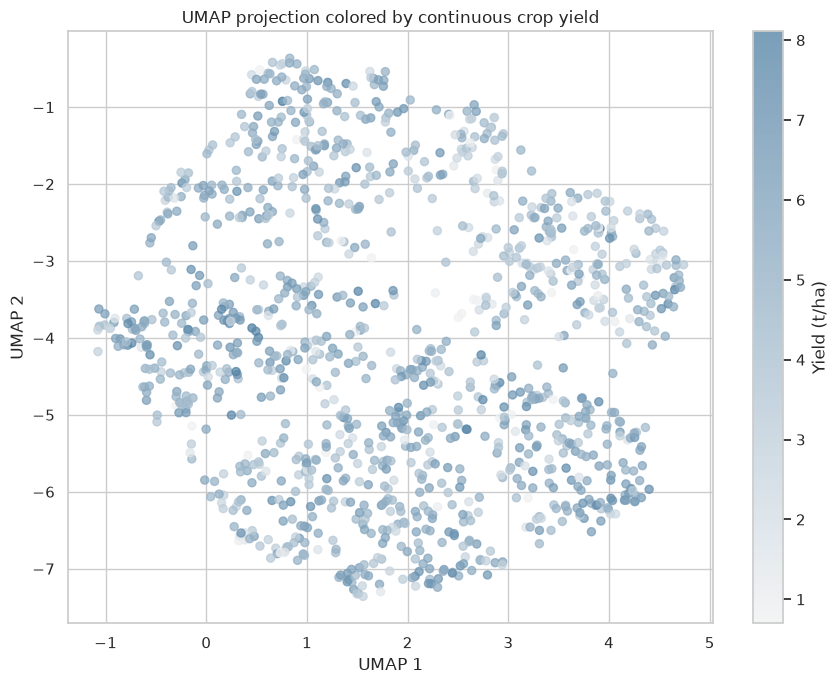

In [22]:
try:
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="IProgress not found.*")
        import umap.umap_ as umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False

if UMAP_AVAILABLE:
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=15,
        min_dist=0.1,
        metric="euclidean",
        random_state=RANDOM_STATE,
    )
    X_umap = reducer.fit_transform(X_scaled)

    umap_scores = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
    umap_scores[TARGET_COLUMN] = df[TARGET_COLUMN].to_numpy()
    umap_scores.to_csv(TABLES_DIR / "umap_scores.csv", index=False)

    fig, ax = plt.subplots(figsize=(9, 7))
    points = ax.scatter(
        umap_scores["UMAP1"],
        umap_scores["UMAP2"],
        c=umap_scores[TARGET_COLUMN],
        cmap=TARGET_CMAP,
        s=34,
        alpha=0.72,
    )
    cbar = fig.colorbar(points, ax=ax)
    cbar.set_label("Yield (t/ha)")
    ax.set(title="UMAP projection colored by continuous crop yield", xlabel="UMAP 1", ylabel="UMAP 2")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "13_umap_by_target.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("UMAP skipped: install 'umap-learn' to run this optional section.")


# Part VII — Reproducible EDA summary

## 21. Export an execution summary

The summary records the principal analytical choices and strongest exploratory associations without converting them into model-selection decisions.


In [23]:
eda_summary = {
    "dataset": "synthetic_crop_yield",
    "task_type": "regression",
    "input_file": str(PROCESSED_DATA_PATH.relative_to(PROJECT_ROOT)),
    "target_column": TARGET_COLUMN,
    "n_observations": int(len(df)),
    "n_numerical_features": int(len(NUMERICAL_COLUMNS)),
    "n_categorical_features": int(len(CATEGORICAL_COLUMNS)),
    "top_numerical_features_by_abs_spearman": correlation_tests.head(5)["feature"].tolist(),
    "top_numerical_features_by_quantile_profile_range": profile_strength.head(5)["feature"].tolist(),
    "top_categorical_features_by_abs_cliffs_delta": categorical_target_tests.head(5)["feature"].tolist(),
    "pca_pc1_variance_ratio": float(pca_2d.explained_variance_ratio_[0]),
    "pca_pc2_variance_ratio": float(pca_2d.explained_variance_ratio_[1]),
    "umap_executed": bool(UMAP_AVAILABLE),
}

with (RESULTS_DIR / "eda_summary.json").open("w", encoding="utf-8") as file:
    json.dump(eda_summary, file, indent=2)

print(json.dumps(eda_summary, indent=2))


{
  "dataset": "synthetic_crop_yield",
  "task_type": "regression",
  "input_file": "data/synthetic_crop_yield/processed_data/synthetic_crop_yield_1200_processed.csv",
  "target_column": "yield_t_ha",
  "n_observations": 1200,
  "n_numerical_features": 13,
  "n_categorical_features": 6,
  "top_numerical_features_by_abs_spearman": [
    "pest_pressure_score_0_10",
    "season_rainfall_mm",
    "soil_organic_matter_pct",
    "nitrogen_kg_ha",
    "solar_radiation_mj_m2_day"
  ],
  "top_numerical_features_by_quantile_profile_range": [
    "mean_temperature_c",
    "soil_moisture_pct",
    "pest_pressure_score_0_10",
    "season_rainfall_mm",
    "nitrogen_kg_ha"
  ],
  "top_categorical_features_by_abs_cliffs_delta": [
    "drought_event",
    "cultivar_improved",
    "organic_management",
    "irrigation_system_drip",
    "previous_legume_crop"
  ],
  "pca_pc1_variance_ratio": 0.09055075559962208,
  "pca_pc2_variance_ratio": 0.06333287412627628,
  "umap_executed": true
}


## 22. What this notebook does — and what it does not do

This notebook has characterized the continuous target, inspected numerical and categorical predictor relationships with yield, compared several association measures, exposed nonlinear trends through quantile profiles, and visualized multivariable geometry.

It has **not** evaluated a regression model. In particular:

- correlation is not predictive performance;
- a nonlinear visual pattern is not a fitted response function;
- PCA/t-SNE/UMAP gradients are not cross-validated predictions;
- statistical significance does not determine which features should enter a final model;
- feature selection or transformations informed by the complete target should not be carried into model evaluation without being re-estimated inside the training data.

The next stage must introduce train/validation/test separation and leakage-safe modelling workflows.
